# 03 Feature Analysis and Split

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

PROCESSED = Path("../data/processed")
RESULTS = Path("../results")
MODELS = Path("../models")
FIG = RESULTS / "figures"
MODELS.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

DEMOGRAPHIC = ["city", "registered_via", "gender", "age", "tenure_days", "has_member"]
BILLING = ["has_tx", "tx_count", "total_paid", "avg_plan_days", "auto_renew_ratio", "cancel_count", "discount_count",
           "n_payment_methods", "last_payment_method", "last_plan_days", "last_amount_paid", "last_auto_renew",
           "last_is_cancel", "days_since_last_tx", "days_until_expiration"]
LISTENING = ["has_logs", "active_days", "total_hours", "secs_per_day", "songs_per_day", "unique_song_ratio", "skip_ratio",
             "complete_ratio", "last7_share", "active_days_7d", "days_since_last_active", "daily_secs_cv"]
FEATURES = DEMOGRAPHIC + BILLING + LISTENING
CATEGORICAL = ["city", "registered_via", "last_payment_method"]
(MODELS / "features.json").write_text(json.dumps({"features": FEATURES, "categorical": CATEGORICAL,
    "groups": {"demographic": DEMOGRAPHIC, "billing": BILLING, "listening": LISTENING}}, indent=1))

df = pd.read_parquet(PROCESSED / "features_train.parquet")
print(df.shape)

(946686, 35)


## Train Validation Test Split

In [2]:
idx_trval, idx_test = train_test_split(df.index, test_size=0.20, stratify=df.is_churn, random_state=42)
idx_train, idx_val = train_test_split(idx_trval, test_size=0.125, stratify=df.is_churn[idx_trval], random_state=42)
df["split"] = "train"
df.loc[idx_val, "split"] = "val"
df.loc[idx_test, "split"] = "test"
split_table = df.groupby("split").is_churn.agg(rows="size", churn_rate="mean")
print(split_table)

df[["msno", "split"]].to_csv(PROCESSED / "split_assignments.csv", index=False)
for name in ["train", "val", "test"]:
    part = df[df.split == name]
    part.drop(columns=["split", "is_churn"]).to_parquet(PROCESSED / f"X_{name}.parquet", index=False, compression="zstd")
    part[["msno", "is_churn"]].to_parquet(PROCESSED / f"y_{name}.parquet", index=False)

tr = df[df.split == "train"]  # all analysis below uses the training split only
rate = tr.is_churn.mean()

         rows  churn_rate
split                    
test   189338    0.089940
train  662679    0.089942
val     94669    0.089945


## Churn Rate by Feature

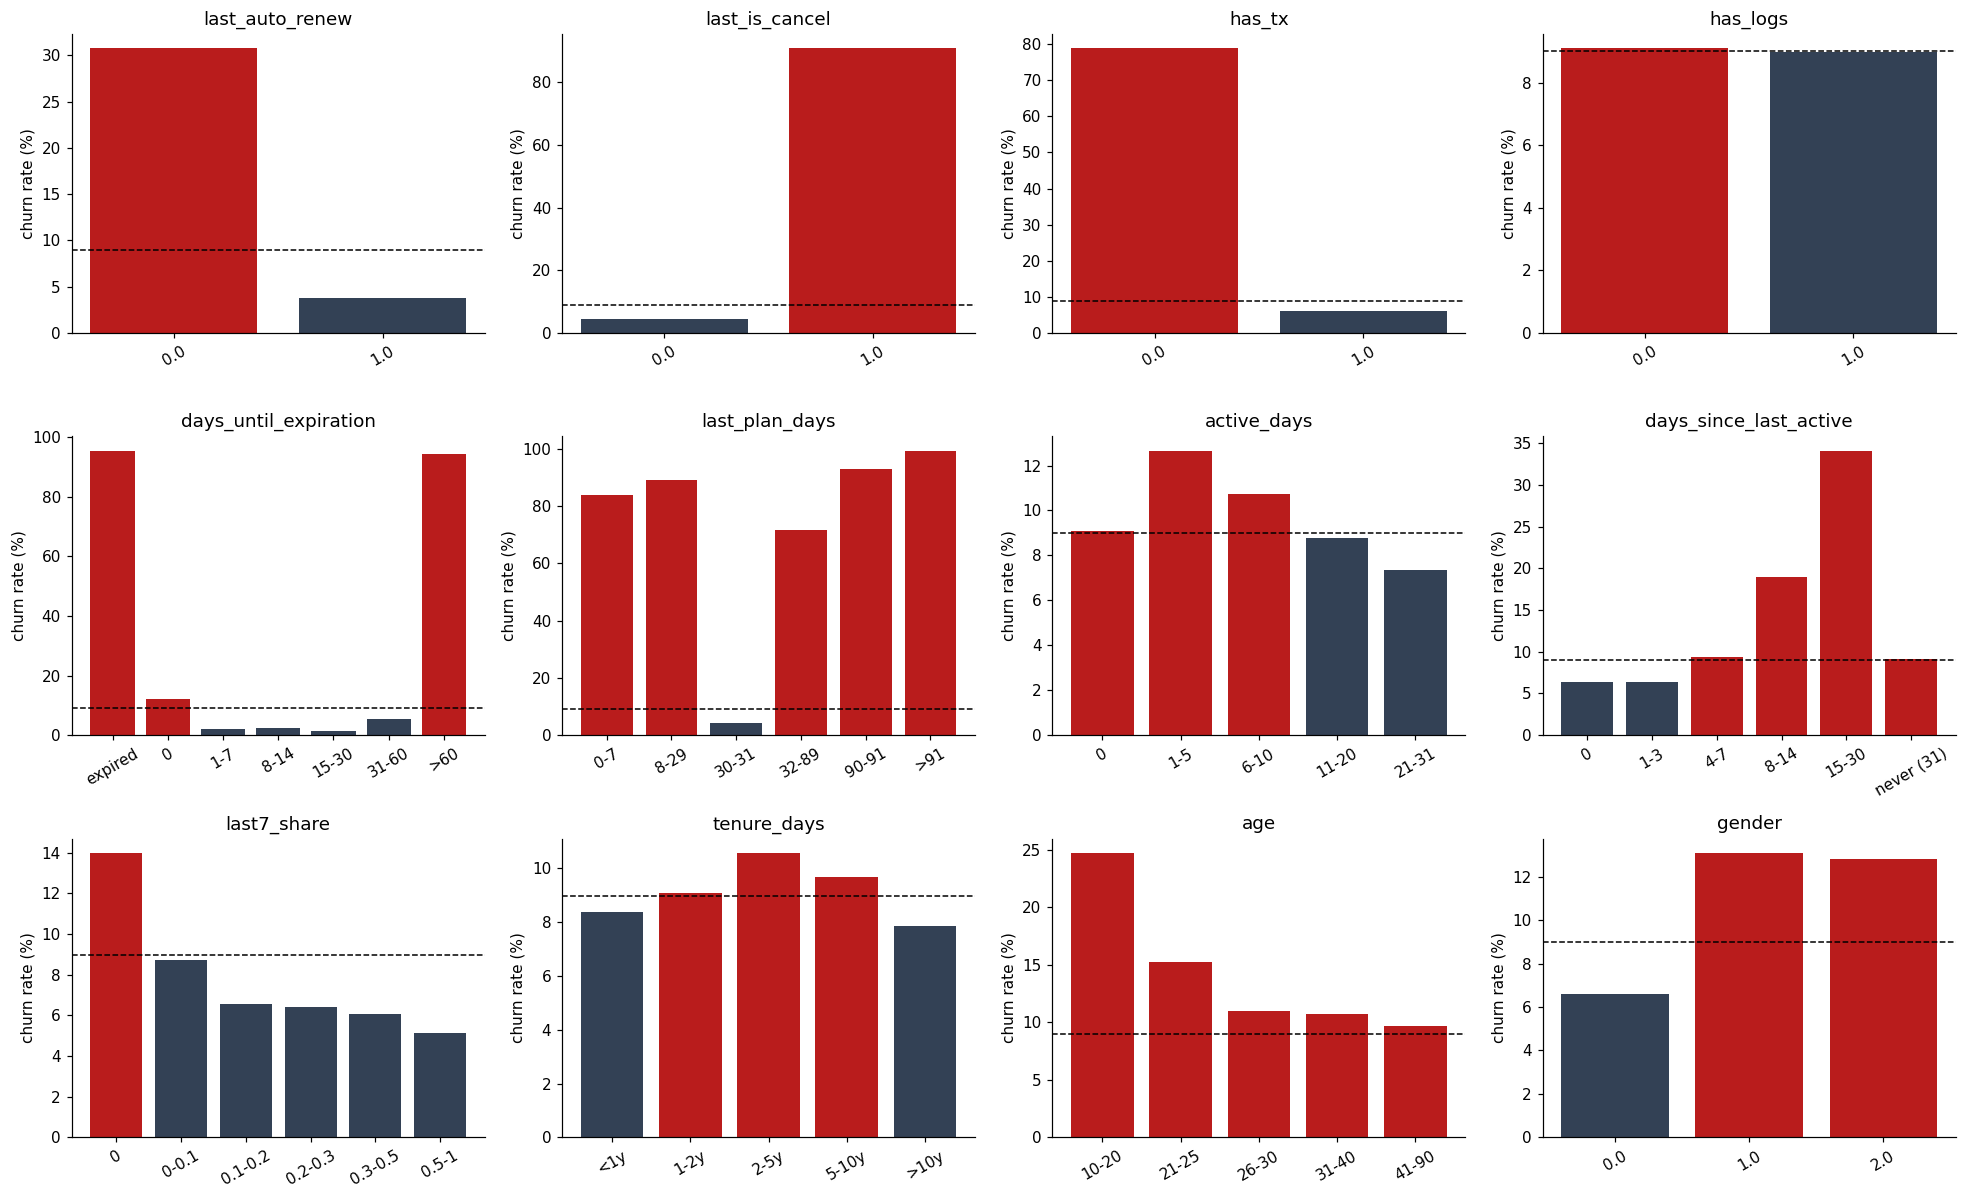

In [3]:
def churn_by(col, bins=None, labels=None):
    key = pd.cut(tr[col], bins=bins, labels=labels, include_lowest=True) if bins is not None else tr[col]
    t = tr.groupby(key, observed=True).is_churn.agg(n="size", churn_rate="mean").reset_index()
    t.columns = ["group", "n", "churn_rate"]
    t["group"] = t.group.astype(str)
    return t

breakdowns = {
    "last_auto_renew": churn_by("last_auto_renew"),
    "last_is_cancel": churn_by("last_is_cancel"),
    "has_tx": churn_by("has_tx"),
    "has_logs": churn_by("has_logs"),
    "days_until_expiration": churn_by("days_until_expiration", [-np.inf, -1, 0, 7, 14, 30, 60, np.inf],
                                      ["expired", "0", "1-7", "8-14", "15-30", "31-60", ">60"]),
    "last_plan_days": churn_by("last_plan_days", [-np.inf, 7, 29, 31, 89, 91, np.inf], ["0-7", "8-29", "30-31", "32-89", "90-91", ">91"]),
    "active_days": churn_by("active_days", [-np.inf, 0, 5, 10, 20, 31], ["0", "1-5", "6-10", "11-20", "21-31"]),
    "days_since_last_active": churn_by("days_since_last_active", [-np.inf, 0, 3, 7, 14, 30, np.inf],
                                       ["0", "1-3", "4-7", "8-14", "15-30", "never (31)"]),
    "last7_share": churn_by("last7_share", [-np.inf, 0, 0.1, 0.2, 0.3, 0.5, 1.0], ["0", "0-0.1", "0.1-0.2", "0.2-0.3", "0.3-0.5", "0.5-1"]),
    "tenure_days": churn_by("tenure_days", [-np.inf, 365, 730, 1825, 3650, np.inf], ["<1y", "1-2y", "2-5y", "5-10y", ">10y"]),
    "age": churn_by("age", [9, 20, 25, 30, 40, 90], ["10-20", "21-25", "26-30", "31-40", "41-90"]),
    "gender": churn_by("gender"),
}
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, (name, t) in zip(axes.ravel(), breakdowns.items()):
    ax.bar(t.group, t.churn_rate * 100, color=np.where(t.churn_rate > rate, "#B91C1C", "#334155"))
    ax.axhline(rate * 100, color="k", ls="--", lw=1)
    ax.set(title=name, ylabel="churn rate (%)"); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(FIG / "feature_churn_rates.png"); plt.show()

## Feature Distributions by Class

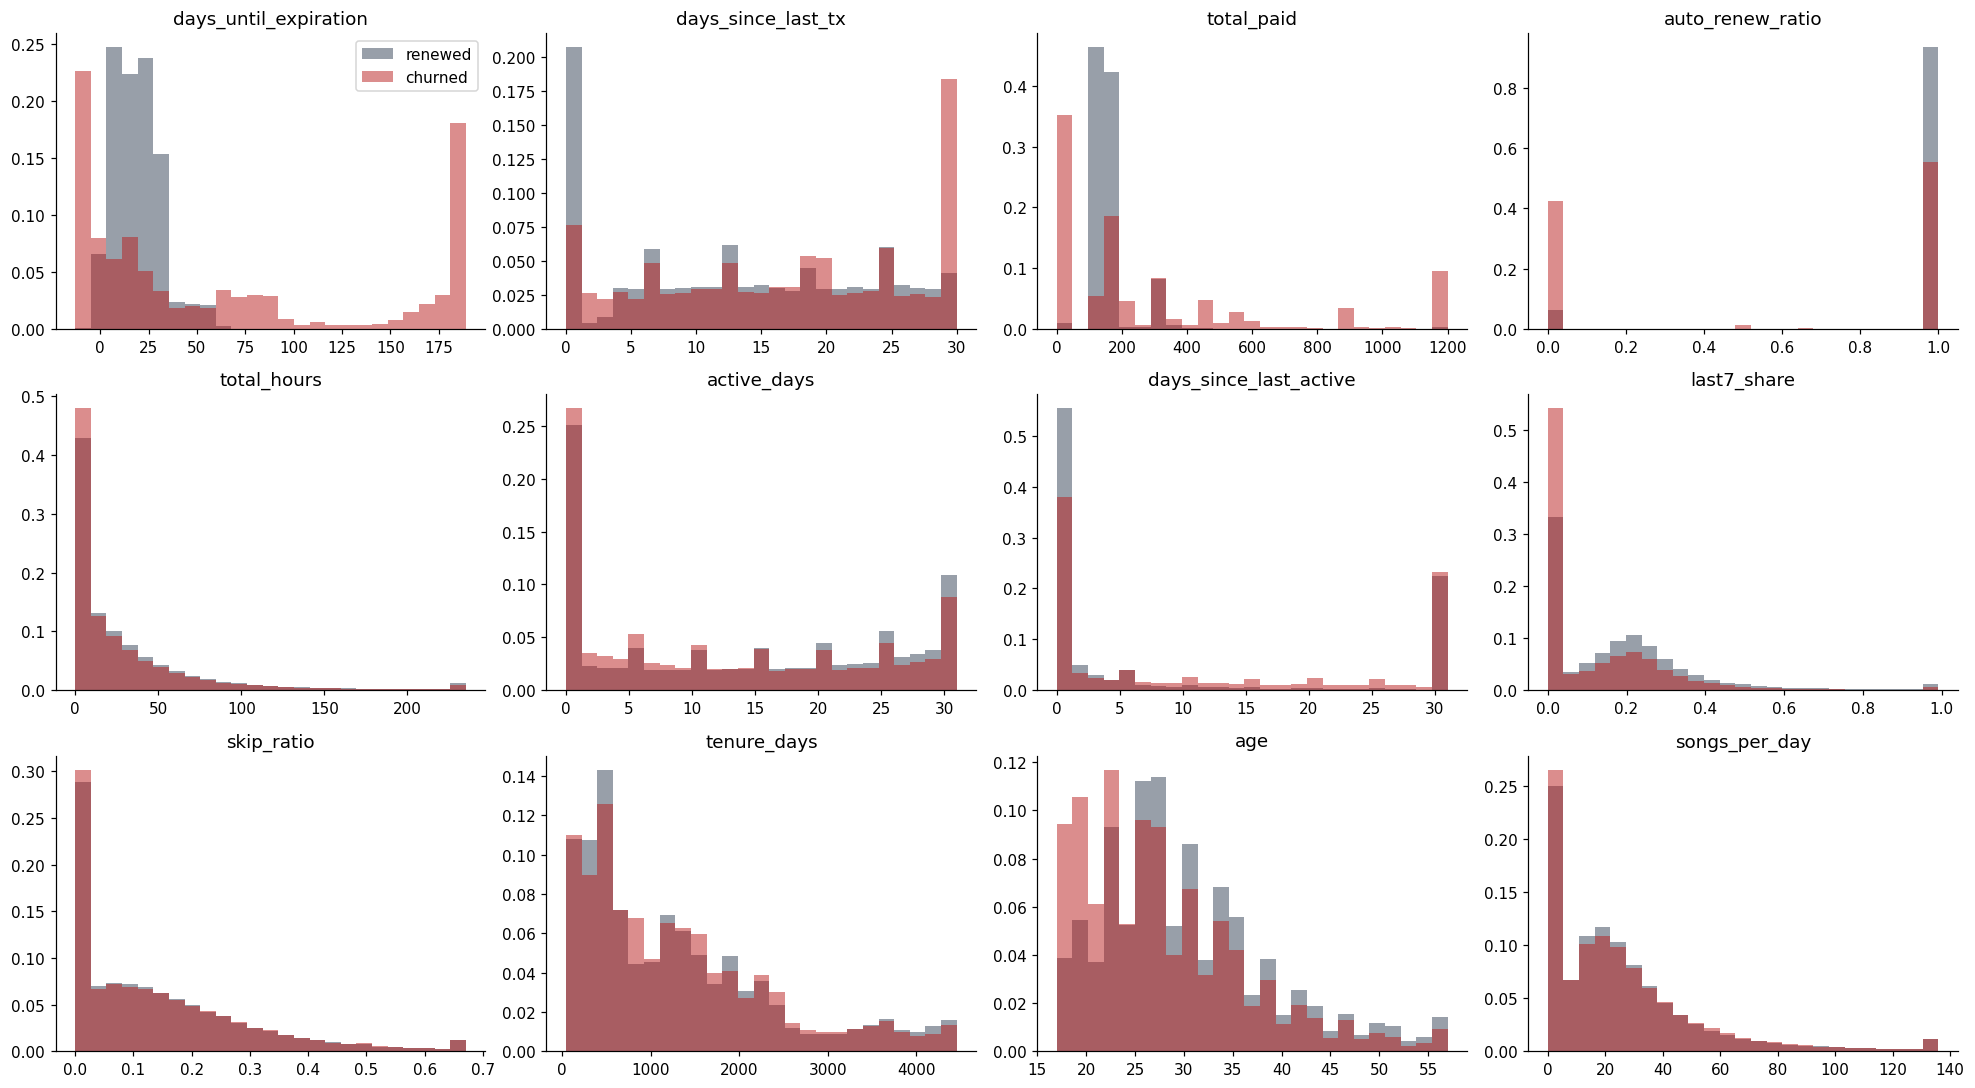

In [4]:
HIST = ["days_until_expiration", "days_since_last_tx", "total_paid", "auto_renew_ratio", "total_hours", "active_days",
        "days_since_last_active", "last7_share", "skip_ratio", "tenure_days", "age", "songs_per_day"]
feature_hists = {}
fig, axes = plt.subplots(3, 4, figsize=(18, 10))
for ax, col in zip(axes.ravel(), HIST):
    x = tr[col].dropna()
    edges = np.linspace(*np.quantile(x, [0.01, 0.99]), 26)
    h = {}
    for label, y in [("renewed", 0), ("churned", 1)]:
        v = tr.loc[tr.is_churn == y, col].dropna().clip(edges[0], edges[-1])
        h[label] = (np.histogram(v, bins=edges)[0] / len(v)).round(5).tolist()
        ax.stairs(h[label], edges, fill=True, alpha=0.5, label=label, color="#B91C1C" if y else "#334155")
    feature_hists[col] = {"edges": edges.round(4).tolist(), **h}
    ax.set(title=col)
axes[0, 0].legend()
plt.tight_layout(); plt.savefig(FIG / "feature_distributions.png"); plt.show()

## Single Feature Ranking Power

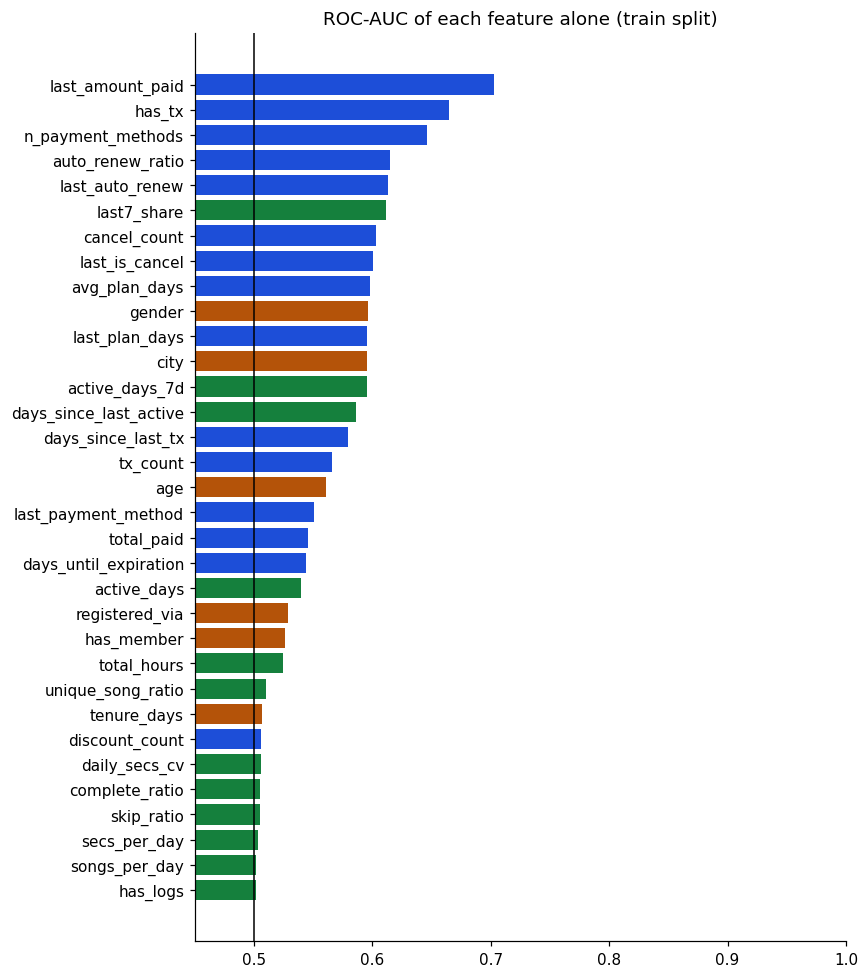

,feature,auc,direction,group
16,last_amount_paid,0.703,higher means more churn,billing
6,has_tx,0.664,lower means more churn,billing
13,n_payment_methods,0.646,lower means more churn,billing
10,auto_renew_ratio,0.615,lower means more churn,billing
17,last_auto_renew,0.613,lower means more churn,billing
29,last7_share,0.611,lower means more churn,listening
11,cancel_count,0.603,higher means more churn,billing
18,last_is_cancel,0.600,higher means more churn,billing
9,avg_plan_days,0.598,higher means more churn,billing
2,gender,0.596,higher means more churn,demographic


In [5]:
uni = []
for col in FEATURES:
    x = tr[col].fillna(tr[col].median())
    auc = roc_auc_score(tr.is_churn, x)
    uni.append({"feature": col, "auc": max(auc, 1 - auc), "direction": "higher means more churn" if auc >= 0.5 else "lower means more churn",
                "group": next(g for g, fs in [("demographic", DEMOGRAPHIC), ("billing", BILLING), ("listening", LISTENING)] if col in fs)})
uni = pd.DataFrame(uni).sort_values("auc", ascending=False)
fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(uni.feature[::-1], uni.auc[::-1], color=uni.group[::-1].map({"billing": "#1D4ED8", "listening": "#15803D", "demographic": "#B45309"}))
ax.axvline(0.5, color="k", lw=1); ax.set(title="ROC-AUC of each feature alone (train split)", xlim=(0.45, 1))
plt.tight_layout(); plt.savefig(FIG / "feature_single_auc.png"); plt.show()
uni.head(12).round(3)

## Correlation Between Features

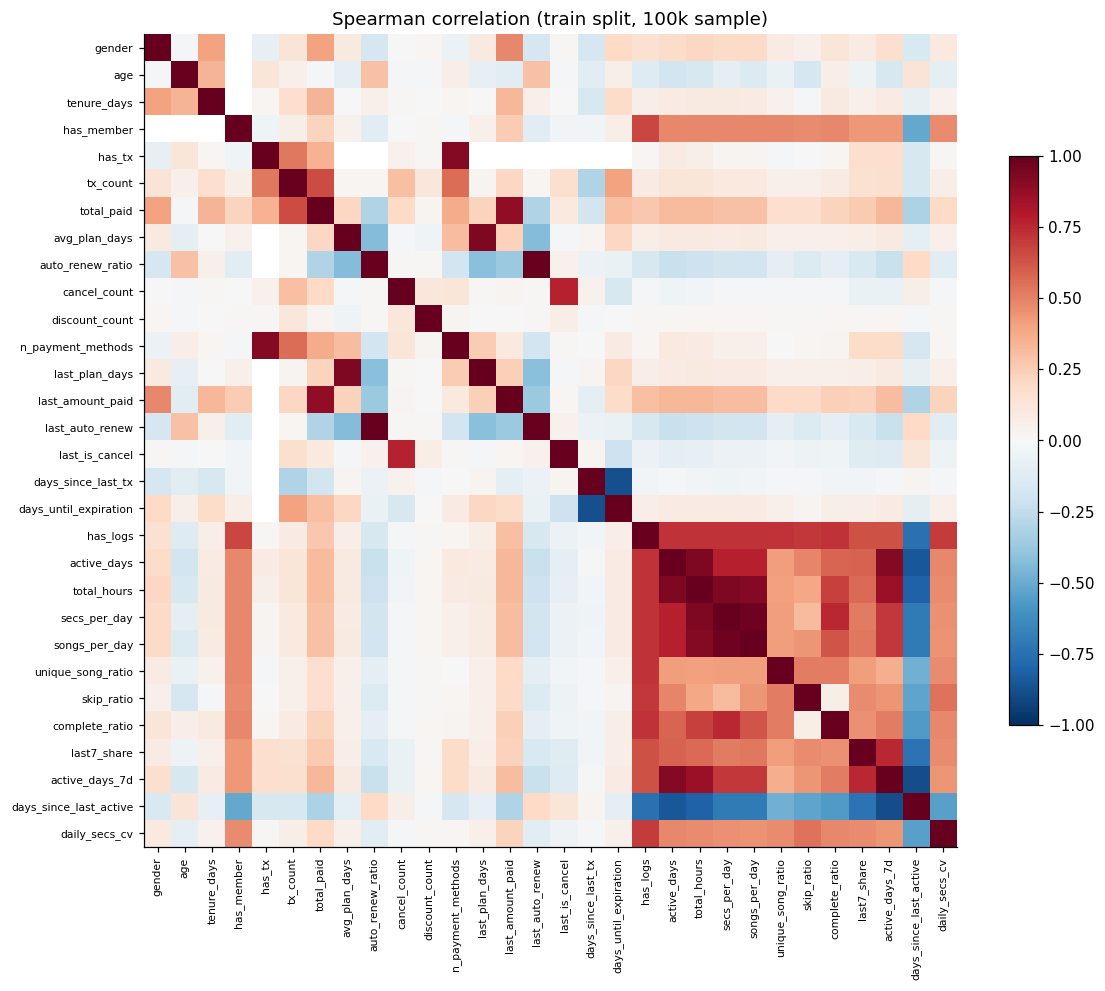

auto_renew_ratio  last_auto_renew      1.00
secs_per_day      songs_per_day        0.97
total_hours       secs_per_day         0.93
avg_plan_days     last_plan_days       0.93
active_days       total_hours          0.93
                  active_days_7d       0.92
has_tx            n_payment_methods    0.92
total_hours       songs_per_day        0.92
dtype: float64

In [6]:
NUM = [c for c in FEATURES if c not in CATEGORICAL]
corr = tr[NUM].sample(100_000, random_state=0).corr(method="spearman").round(2)
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(NUM)), NUM, rotation=90, fontsize=7); ax.set_yticks(range(len(NUM)), NUM, fontsize=7)
fig.colorbar(im, shrink=0.7); ax.set_title("Spearman correlation (train split, 100k sample)")
plt.tight_layout(); plt.savefig(FIG / "feature_correlation.png"); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().sort_values(key=abs, ascending=False)
pairs.head(8)

## Missing Values and Skew

In [7]:
missing = df[FEATURES].isna().mean().mul(100).round(2)
skew = tr[["total_paid", "tx_count", "total_hours", "secs_per_day", "songs_per_day"]].skew().round(1)
print(missing[missing > 0].to_string(), "\n")
print(skew.to_string())

city                     11.32
registered_via           11.32
gender                   11.32
age                      60.19
tenure_days              11.32
avg_plan_days             3.85
auto_renew_ratio          3.85
last_payment_method       3.85
last_plan_days            3.85
last_amount_paid          3.85
last_auto_renew           3.85
last_is_cancel            3.85
days_since_last_tx        3.85
days_until_expiration     3.85 

total_paid        9.600000
tx_count         22.799999
total_hours       3.800000
secs_per_day      3.200000
songs_per_day     4.200000


## Feature Summary Statistics

In [8]:
desc = tr[FEATURES].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T
desc["missing_pct"] = tr[FEATURES].isna().mean() * 100
desc["unique"] = tr[FEATURES].nunique()
desc["zero_pct"] = (tr[FEATURES] == 0).mean() * 100
desc["skew"] = tr[FEATURES].skew()
feature_summary = desc[["missing_pct", "unique", "zero_pct", "mean", "std", "min", "1%", "50%", "99%", "max", "skew"]].round(3)
feature_summary

,missing_pct,unique,zero_pct,mean,std,min,1%,50%,99%,max,skew
city,11.314,21,0.000,5.923,6.433,1.0,1.0,1.000,22.000,22.000,1.062000
registered_via,11.314,5,0.000,6.894,1.937,3.0,3.0,7.000,9.000,13.000,-0.731000
gender,11.314,3,48.683,0.688,0.830,0.0,0.0,0.000,2.000,2.000,0.635000
age,60.260,81,0.000,29.905,8.854,10.0,17.0,28.000,57.000,90.000,1.167000
tenure_days,11.314,4745,0.001,1294.054,1097.400,-24.0,43.0,1031.000,4455.980,4753.000,1.142000
has_member,0.000,2,11.314,0.887,0.317,0.0,0.0,1.000,1.000,1.000,-2.443000
has_tx,0.000,2,3.857,0.961,0.193,0.0,0.0,1.000,1.000,1.000,-4.792000
tx_count,0.000,56,3.857,1.164,1.245,0.0,0.0,1.000,3.000,172.000,22.833000
total_paid,0.000,950,4.007,169.015,228.214,0.0,0.0,149.000,1200.000,8850.000,9.626000
avg_plan_days,3.857,290,0.000,33.692,31.704,0.0,30.0,30.000,195.000,450.000,10.077000


## Churn Rate by Feature Decile

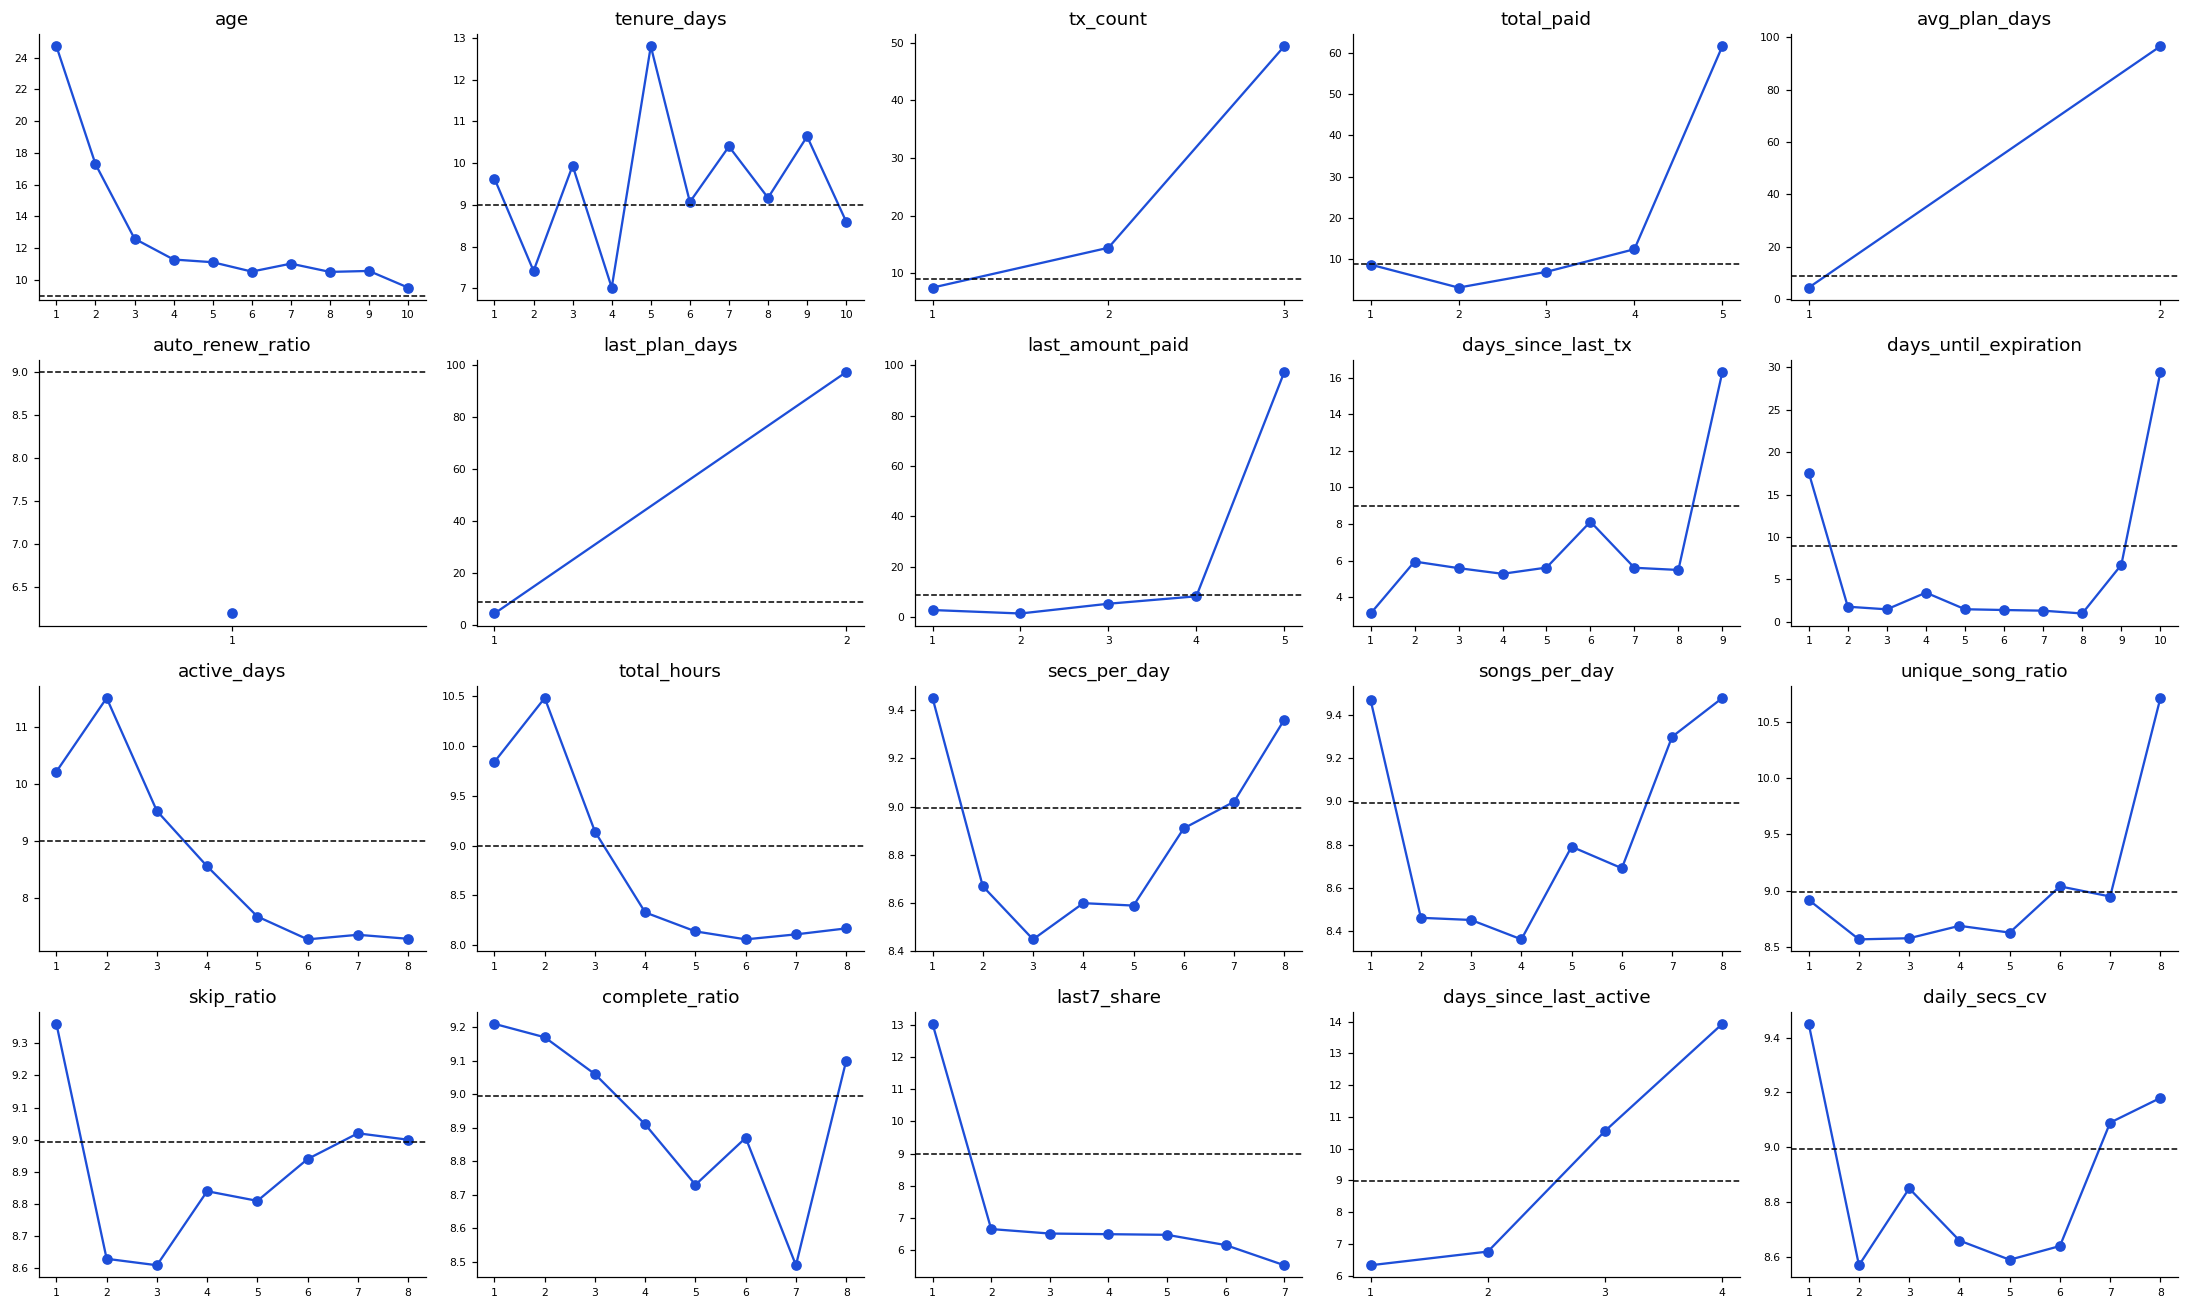

In [9]:
DECILE = [c for c in NUM if tr[c].nunique() > 10]
decile_curves = {}
for col in DECILE:
    q = pd.qcut(tr[col], 10, labels=False, duplicates="drop")  # tied values stay in one bin
    g = tr.groupby(q).agg(lo=(col, "min"), hi=(col, "max"), churn_rate=("is_churn", "mean"), n=("is_churn", "size"))
    decile_curves[col] = g.round(4).to_dict(orient="records")
fig, axes = plt.subplots(4, 5, figsize=(20, 12))
for ax, col in zip(axes.ravel(), DECILE):
    d = pd.DataFrame(decile_curves[col])
    ax.plot(range(1, len(d) + 1), d.churn_rate * 100, "o-", color="#1D4ED8"); ax.axhline(rate * 100, color="k", ls="--", lw=1)
    ax.set(title=col, xticks=range(1, len(d) + 1)); ax.tick_params(labelsize=7)
for ax in axes.ravel()[len(DECILE):]:
    ax.axis("off")
plt.tight_layout(); plt.savefig(FIG / "feature_decile_churn.png"); plt.show()

## Missing Values vs Churn

In [10]:
miss_churn = []
for col in [c for c in FEATURES if tr[c].isna().any()]:
    m = tr[col].isna()
    miss_churn.append({"feature": col, "missing_pct": float(m.mean() * 100),
                       "churn_missing": float(tr.is_churn[m].mean()), "churn_present": float(tr.is_churn[~m].mean())})
miss_churn = pd.DataFrame(miss_churn).drop_duplicates(subset=["missing_pct", "churn_missing"])
miss_churn.round(3)

,feature,missing_pct,churn_missing,churn_present
0,city,11.314,0.053,0.095
3,age,60.260,0.062,0.133
5,avg_plan_days,3.857,0.788,0.062


## Distribution Shift Between Splits

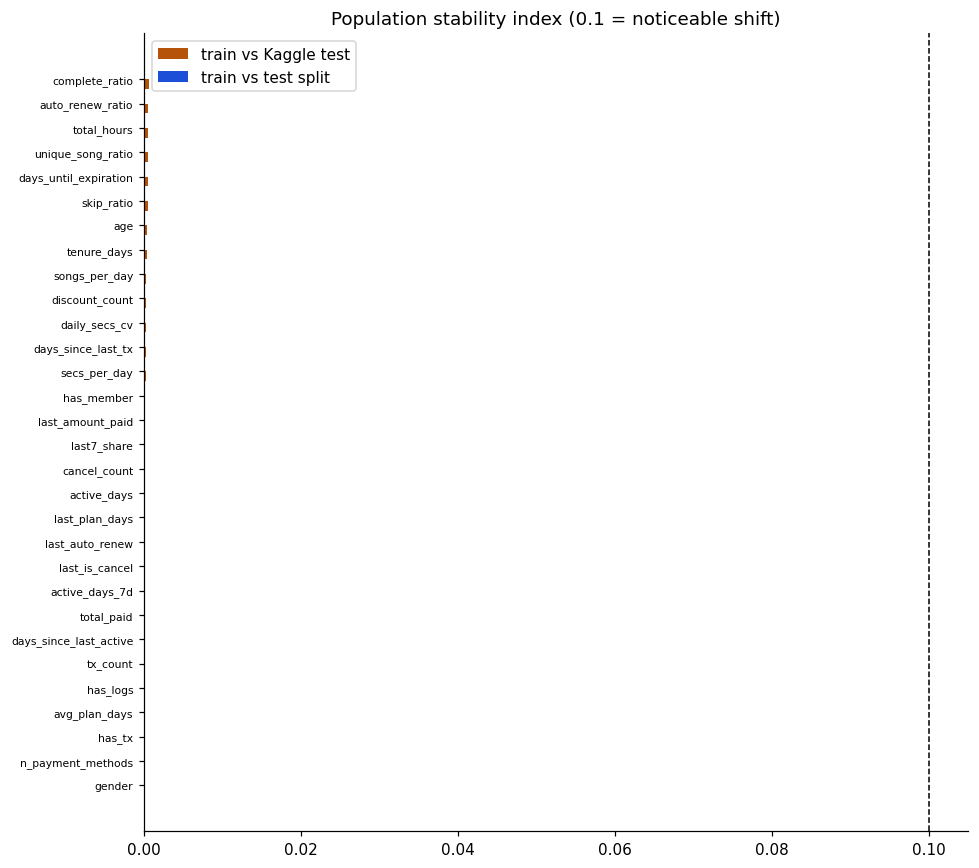

,feature,val,test,kaggle_test
25,complete_ratio,0.0001,0.0001,0.0007
8,auto_renew_ratio,0.0000,0.0000,0.0005
20,total_hours,0.0001,0.0000,0.0005
23,unique_song_ratio,0.0002,0.0000,0.0005
17,days_until_expiration,0.0001,0.0000,0.0004
24,skip_ratio,0.0001,0.0001,0.0004
1,age,0.0002,0.0000,0.0004
2,tenure_days,0.0002,0.0000,0.0003
22,songs_per_day,0.0000,0.0001,0.0003
10,discount_count,0.0001,0.0001,0.0003


In [11]:
kaggle = pd.read_parquet(PROCESSED / "features_kaggle_test.parquet")

def psi(ref, cur, bins=10):
    ref, cur = ref.dropna(), cur.dropna()
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
    if len(edges) < 3:
        edges = np.unique(np.r_[ref.min() - 1, np.sort(ref.unique())[:bins], ref.max() + 1])
    a = np.histogram(ref.clip(edges[0], edges[-1]), edges)[0] / len(ref) + 1e-6
    b = np.histogram(cur.clip(edges[0], edges[-1]), edges)[0] / len(cur) + 1e-6
    return float(np.sum((b - a) * np.log(b / a)))

shift = pd.DataFrame([{"feature": c, "val": psi(tr[c], df.loc[df.split == "val", c]), "test": psi(tr[c], df.loc[df.split == "test", c]),
                       "kaggle_test": psi(tr[c], kaggle[c])} for c in NUM]).sort_values("kaggle_test", ascending=False)
fig, ax = plt.subplots(figsize=(9, 8))
y = np.arange(len(shift))
ax.barh(y + 0.2, shift.kaggle_test, 0.4, label="train vs Kaggle test", color="#B45309")
ax.barh(y - 0.2, shift.test, 0.4, label="train vs test split", color="#1D4ED8")
ax.axvline(0.1, color="k", ls="--", lw=1); ax.set_yticks(y, shift.feature, fontsize=7); ax.invert_yaxis()
ax.set(title="Population stability index (0.1 = noticeable shift)"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "feature_shift.png"); plt.show()
shift.head(10).round(4)

In [12]:
eda = {"churn_rate": float(rate),
       "feature_summary": feature_summary.reset_index(names="feature").to_dict(orient="records"),
       "decile_curves": decile_curves, "missing_churn": miss_churn.round(4).to_dict(orient="records"),
       "shift": shift.round(4).to_dict(orient="records"),
       "breakdowns": {k: v.to_dict(orient="records") for k, v in breakdowns.items()},
       "missing_pct": {k: float(v) for k, v in missing[missing > 0].items()},
       "skew": {k: float(v) for k, v in skew.items()},
       "split": {k: {"rows": int(v["rows"]), "churn_rate": float(v["churn_rate"])} for k, v in split_table.iterrows()},
       "single_auc": uni.round(4).to_dict(orient="records"),
       "feature_hists": feature_hists,
       "corr": {"features": NUM, "matrix": corr.values.tolist()}}
(RESULTS / "eda_summary.json").write_text(json.dumps(eda, default=float))
print("saved split files, models/features.json and results/eda_summary.json")

saved split files, models/features.json and results/eda_summary.json
